In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
root=Path("..")/"Experiment_Results"/"HasilEksperimenTahap2"/"Tahap2A"
sources = {
    "Crossover": root / "Crossover",
    "Population_500": root / "Population" / "500",
}
dataframes=[]
for source_name, folder in sources.items():
    csv_files = sorted(folder.rglob("*.csv"))
    print(f"{source_name}: ditemukan {len(csv_files)} file CSV")

    for csv_file in csv_files:
        df = pd.read_csv(csv_file)

        # Menyimpan asal data agar baris gabungan bisa dilacak
        df["source_group"] = source_name
        df["source_file"] = str(csv_file.relative_to(root))

        dataframes.append(df)
if dataframes:
    df_all=pd.concat(dataframes, ignore_index=True)
else:
    df_all=pd.DataFrame()
    print("Tidak ada file CSV yang berhasil dibaca.")

Crossover: ditemukan 36 file CSV
Population_500: ditemukan 12 file CSV


In [4]:
summary_All_Crossover=df_all.groupby(["grid_rows", "pc", "map_type"], as_index=False).agg(
    mean_cost=("best_cost", "mean"),
    best_run=("best_cost", "min"),
    worst_run=("best_cost", "max"),
    std_cost=("best_cost", "std"),
    total_runs=("best_cost", "count")
)
display(summary_All_Crossover)

,grid_rows,pc,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
0,10,0.80,Cluster,2.511111,2.500000,2.700000,0.034978,90
1,10,0.80,Maze,3.337037,3.333333,3.500000,0.024705,90
2,10,0.80,Random,2.603042,2.416667,2.928571,0.159234,180
3,10,0.85,Cluster,2.508889,2.500000,2.700000,0.032306,90
4,10,0.85,Maze,3.337037,3.333333,3.500000,0.024705,90
5,10,0.85,Random,2.601786,2.416667,2.857143,0.153652,180
6,10,0.90,Cluster,2.505556,2.500000,2.600000,0.023034,90
7,10,0.90,Maze,3.338889,3.333333,3.500000,0.030085,90
8,10,0.90,Random,2.597553,2.416667,2.928571,0.162228,180
9,10,0.95,Cluster,2.514444,2.500000,2.600000,0.035351,90


In [5]:
table_random=summary_All_Crossover[summary_All_Crossover["map_type"]=="Random"].sort_values("pc")
display(table_random)
table_cluster=summary_All_Crossover[summary_All_Crossover["map_type"]=="Cluster"].sort_values("pc")
display(table_cluster)
table_Maze=summary_All_Crossover[summary_All_Crossover["map_type"]=="Maze"].sort_values("pc")
display(table_Maze)

,grid_rows,pc,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
2,10,0.80,Random,2.603042,2.416667,2.928571,0.159234,180
14,20,0.80,Random,6.249712,6.025000,6.564103,0.217253,180
26,40,0.80,Random,6.687722,6.525641,6.943750,0.107719,180
17,20,0.85,Random,6.248864,6.025000,6.538462,0.217056,180
29,40,0.85,Random,6.677556,6.512821,6.875000,0.106013,180
5,10,0.85,Random,2.601786,2.416667,2.857143,0.153652,180
20,20,0.90,Random,6.247885,6.025000,6.512821,0.217210,180
8,10,0.90,Random,2.597553,2.416667,2.928571,0.162228,180
32,40,0.90,Random,6.674054,6.512821,6.881250,0.104363,180
11,10,0.95,Random,2.597884,2.416667,2.857143,0.157586,180


,grid_rows,pc,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
0,10,0.80,Cluster,2.511111,2.500000,2.700000,0.034978,90
12,20,0.80,Cluster,4.794595,4.783784,4.918919,0.020176,90
24,40,0.80,Cluster,5.495197,5.445161,5.741935,0.047264,90
15,20,0.85,Cluster,4.792192,4.783784,4.837838,0.014407,90
27,40,0.85,Cluster,5.484229,5.445161,5.645161,0.036036,90
3,10,0.85,Cluster,2.508889,2.500000,2.700000,0.032306,90
18,20,0.90,Cluster,4.790090,4.783784,4.864865,0.014064,90
6,10,0.90,Cluster,2.505556,2.500000,2.600000,0.023034,90
30,40,0.90,Cluster,5.485520,5.445161,5.606452,0.034365,90
9,10,0.95,Cluster,2.514444,2.500000,2.600000,0.035351,90


,grid_rows,pc,map_type,mean_cost,best_run,worst_run,std_cost,total_runs
1,10,0.80,Maze,3.337037,3.333333,3.500000,0.024705,90
13,20,0.80,Maze,6.813390,6.794872,6.871795,0.018445,90
25,40,0.80,Maze,6.894100,6.834483,7.027586,0.046284,90
16,20,0.85,Maze,6.809402,6.794872,6.846154,0.014408,90
28,40,0.85,Maze,6.892261,6.834483,7.124138,0.047191,90
4,10,0.85,Maze,3.337037,3.333333,3.500000,0.024705,90
19,20,0.90,Maze,6.810256,6.794872,6.846154,0.016217,90
7,10,0.90,Maze,3.338889,3.333333,3.500000,0.030085,90
31,40,0.90,Maze,6.884521,6.834483,6.986207,0.037683,90
10,10,0.95,Maze,3.337037,3.333333,3.500000,0.024705,90


In [6]:
summary_All_Crossover["rank_mean_cost"] = (
    summary_All_Crossover
    .groupby(["grid_rows", "map_type"])["mean_cost"]
    .rank(method="average", ascending=True)
)
avg_rank_All = (
    summary_All_Crossover
    .groupby("pc", as_index=False)
    .agg(
        avg_rank_mean=("rank_mean_cost", "mean"),
        avg_mean_cost=("mean_cost", "mean"),
        avg_std_cost=("std_cost", "mean"),
        jumlah_kombinasi=("rank_mean_cost", "count")
    )
    .sort_values(["avg_mean_cost"])
)
display(avg_rank_All)

,pc,avg_rank_mean,avg_mean_cost,avg_std_cost,jumlah_kombinasi
3,0.95,1.833333,5.036932,0.072173,9
2,0.90,2.111111,5.037147,0.071028,9
1,0.85,2.388889,5.039135,0.071753,9
0,0.80,3.666667,5.042878,0.075118,9


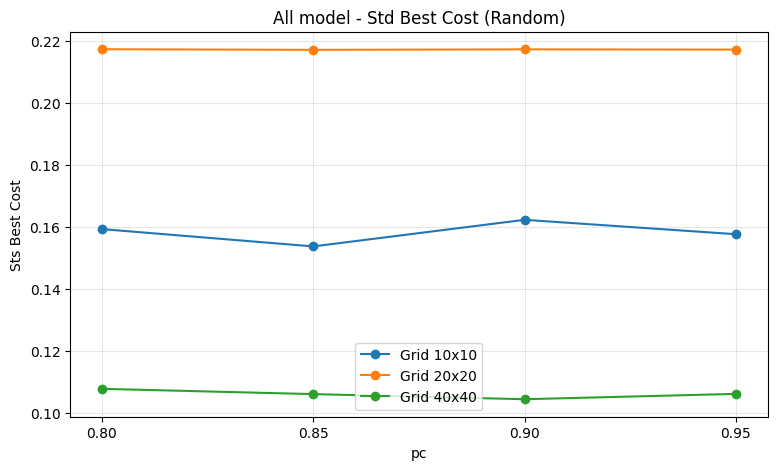

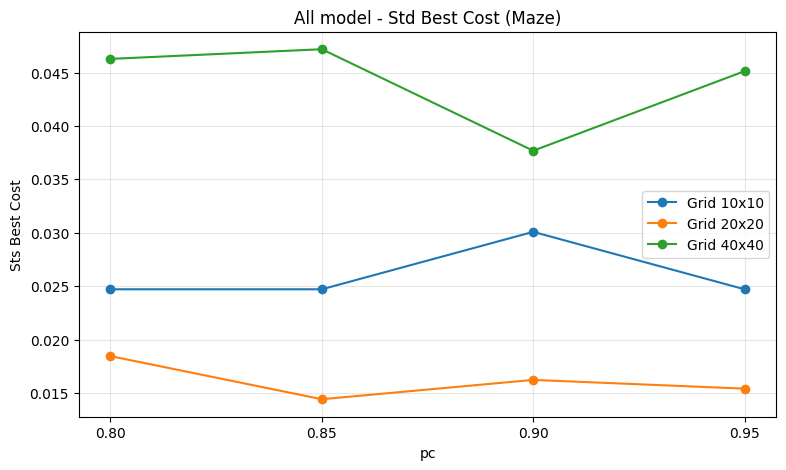

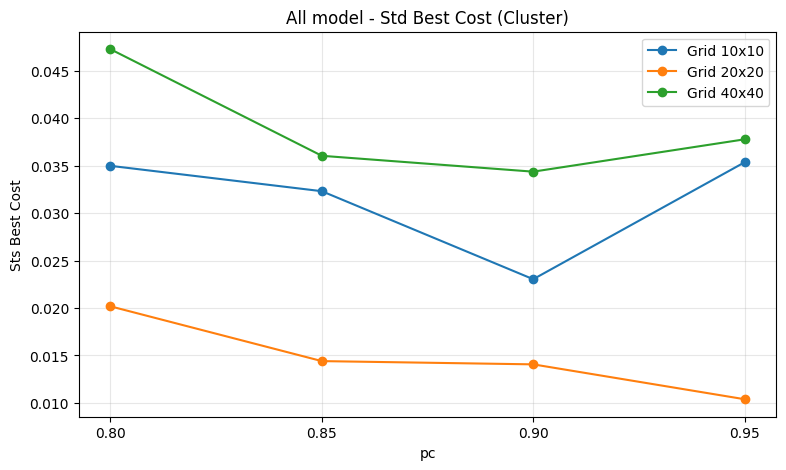

In [8]:
#std cost
map_types = ["Random", "Maze", "Cluster"]

for map_type in map_types:
    data = summary_All_Crossover[
        summary_All_Crossover["map_type"] == map_type
    ].copy()

    plt.figure(figsize=(9, 5))

    for grid_rows in sorted(data["grid_rows"].unique()):
        data_size = (
            data[data["grid_rows"] == grid_rows]
            .sort_values("pc")
        )

        plt.plot(
            data_size["pc"],
            data_size["std_cost"],
            marker="o",
            label=f"Grid {grid_rows}x{grid_rows}"
        )

    plt.title(f"All model - Std Best Cost ({map_type})")
    plt.xlabel("pc")
    plt.ylabel("Sts Best Cost")
    plt.xticks(sorted(data["pc"].unique()))
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.show()

In [9]:
summary_All_Crossover["rank_std_cost"] = (
    summary_All_Crossover
    .groupby(["grid_rows", "map_type"])["std_cost"]
    .rank(method="average", ascending=True)
)

avg_rank_All_std = (
    summary_All_Crossover
    .groupby("pc", as_index=False)
    .agg(
        avg_rank_std=("rank_std_cost", "mean"),
        avg_std_cost=("std_cost", "mean"),
        jumlah_kombinasi=("rank_std_cost", "count")
    )
    .sort_values([ "avg_std_cost"])
)

print(avg_rank_All_std)

     pc  avg_rank_std  avg_std_cost  jumlah_kombinasi
2  0.90      2.222222      0.071028                 9
1  0.85      1.888889      0.071753                 9
3  0.95      2.444444      0.072173                 9
0  0.80      3.444444      0.075118                 9
